In [1]:
import re
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from collections import Counter

In [2]:
df = pd.read_csv("Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
df.head()

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


In [6]:
df["question"] = df["question"].str.lower()

def split_words(s):
    return re.sub(r'[!"#$%&()*+,\-./:;<=>?@\[\\\]^_`{|}~\t\n]', " ", s).split()

class SimpleTokenizer:
    def __init__(self, texts):
        counts = Counter(w for t in texts for w in split_words(t))
        self.word_index = {w: i + 1 for i, (w, _) in enumerate(counts.most_common())}
        self.index_word = {i: w for w, i in self.word_index.items()}
    def texts_to_sequences(self, texts):
        return [[self.word_index[w] for w in split_words(t) if w in self.word_index] for t in texts]

tokenizer = SimpleTokenizer(df["question"])
seqs = tokenizer.texts_to_sequences(df["question"])

max_len = max(len(s) for s in seqs)
X = torch.tensor([s + [0] * (max_len - len(s)) for s in seqs], dtype=torch.long)
y = torch.tensor(df["answer_id"].values, dtype=torch.long)

class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

In [7]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    optimizer.zero_grad()
    loss = nn.functional.cross_entropy(model(X)[0], y)
    loss.backward()
    optimizer.step()
    if epoch % 10 == 0:
        print(epoch, loss.item())

print("Training finished!")

0 2.4917449951171875
10 1.860968828201294
20 1.210092306137085
30 0.7117026448249817
40 0.39901497960090637
Training finished!


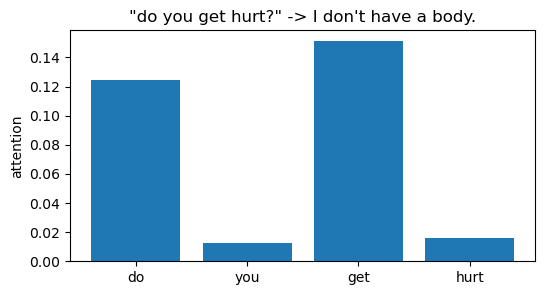

Highest attention: 'get' (0.151)


In [8]:
def show_attention(idx):
    ids = [i for i in X[idx].tolist() if i != 0]
    words = [tokenizer.index_word[i] for i in ids]
    with torch.no_grad():
        pred, weights = model(X[idx:idx+1])
    w = weights[0, :len(words)].tolist()
    plt.figure(figsize=(6, 3))
    plt.bar(words, w)
    plt.title(f'"{df.question[idx]}" -> {df.answer[pred.argmax().item()]}')
    plt.ylabel("attention")
    plt.show()
    print(f"Highest attention: '{words[w.index(max(w))]}' ({max(w):.3f})")

# Step 6: first question
show_attention(0)

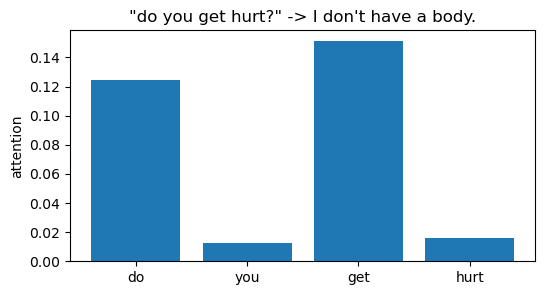

Highest attention: 'get' (0.151)


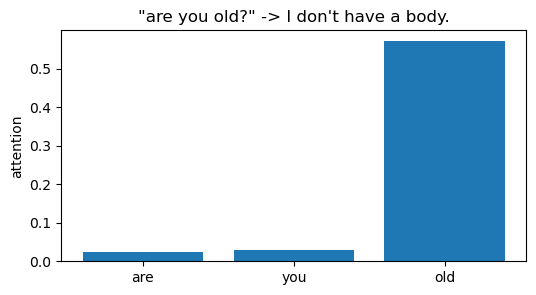

Highest attention: 'old' (0.571)


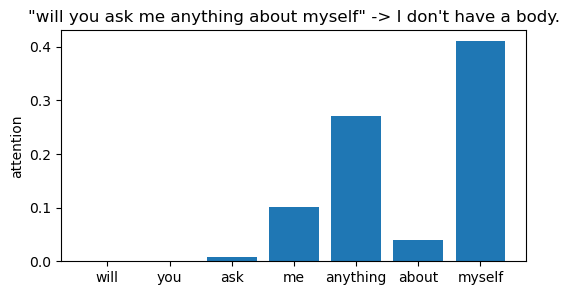

Highest attention: 'myself' (0.410)


In [9]:
# Task 1: three questions from different answer groups
for idx in [0, 14, df.index[df.answer_id == 2][0]]:
    show_attention(idx)

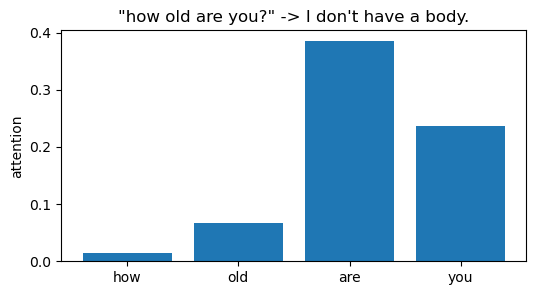

Highest attention: 'are' (0.385)


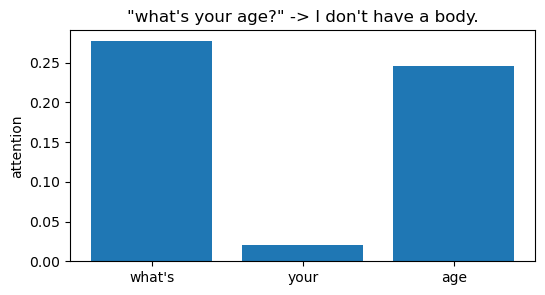

Highest attention: 'what's' (0.277)


In [10]:
# Task 2: similar meaning, different wording
a = df.index[df.question == "how old are you?"][0]
b = df.index[df.question == "what's your age?"][0]
show_attention(a)
show_attention(b)